<a href="https://colab.research.google.com/gist/jteichma/8dbb20e7ec2178e189793ba0e6f5bda4/lecture6_20261028.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tractability of SDE solutions

What can we compute directly when estimating it from simulated paths would be costly?

| Type of tractability | What it gives | Example |
|---|---|---|
| **Explicit solution** | A formula in terms of the driving noise, giving exact updates on a time grid. | Black–Scholes |
| **Explicit transition law** | The conditional distribution at a later time, for direct sampling or integration. | Multivariate OU |
| **Tractable Fourier–Laplace transform** | A formula or small ODE system for a transform; inversion can give quantities such as option prices (Carr-Madan). | CIR and Heston |

Please note that these types can overlap.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, solve_continuous_lyapunov
from scipy.integrate import solve_ivp
from scipy.stats import ncx2

rng = np.random.default_rng(20261026)

# 1. Black–Scholes / geometric Brownian motion

Consider
$$
dS_t=\mu S_t\,dt+\sigma S_t\,dW_t,\qquad S_0=s_0>0.
$$

## Exercise 1.1 — solve the SDE

Apply Itô's formula to $\log S_t$ and show
$$
S_t=S_0\exp\!\left((\mu-\tfrac12\sigma^2)t+\sigma W_t\right).
$$

**Proof sketch.**
For $f(x) = \log(x)$, and since $f'(x)=1/x$ and $f''(x)=-1/x^2$,
$$
d\log S_t=\frac{dS_t}{S_t}-\frac12\frac{d[S]_t}{S_t^2}
=\left(\mu-\frac12\sigma^2\right)dt+\sigma dW_t.
$$
Integrating and exponentiating yields the formula.

## Exercise 1.2 — marginal law and moments

Show
$$
\log S_t\sim N\!\left(\log S_0+(\mu-\tfrac12\sigma^2)t,\sigma^2t\right),
$$
so $S_t$ is lognormal, and prove
$$
\mathbb E[S_t^p]=S_0^p\exp\left(p\mu t+\tfrac12p(p-1)\sigma^2t\right).
$$

**Proof sketch.**
Use $W_t\sim N(0,t)$ and
$$
\mathbb E[e^{aW_t}]=e^{a^2t/2}.
$$

## Illustration — exact transition versus Euler preview

The exact transition is
$$
S_{t+\Delta}=S_t\exp\left((\mu-\tfrac12\sigma^2)\Delta+\sigma\sqrt\Delta Z\right).
$$
Euler uses
$$
S_{n+1}^E=S_n^E+\mu S_n^E\Delta+\sigma S_n^E\Delta W_n.
$$
Both are driven below by the same Brownian increments.

**What to check.** Exponentiate the exact increment of the log-price; Euler freezes the coefficients at the start of each step. Both updates use the same Brownian increments.

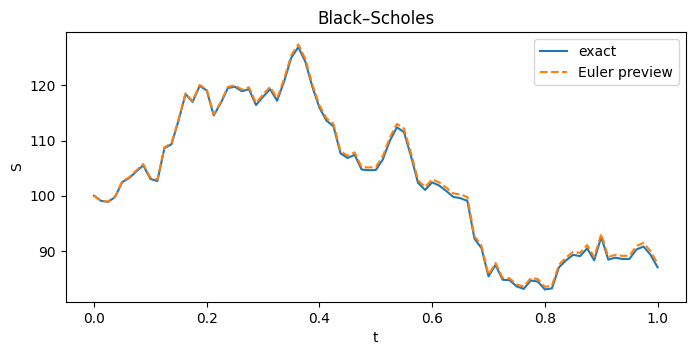

In [2]:
T,N=1.0,80 #Change T to broadcast changes to discretization vs exact method: the bigger T gets, the higher the discrepancy between the 2 methods. Try e.g. T=50.
dt=T/N
s0,mu,sig=100.0,0.08,0.25
dW=np.sqrt(dt)*rng.standard_normal(N)
t=np.linspace(0,T,N+1)
Sx=np.empty(N+1); Se=np.empty(N+1)
Sx[0]=Se[0]=s0
for n in range(N):
    Sx[n+1]=Sx[n]*np.exp((mu-.5*sig**2)*dt+sig*dW[n])
    Se[n+1]=Se[n]+mu*Se[n]*dt+sig*Se[n]*dW[n]
plt.figure(figsize=(8,3.5)); plt.plot(t,Sx,label='exact'); plt.plot(t,Se,'--',label='Euler preview')
plt.xlabel('t'); plt.ylabel('S'); plt.title('Black–Scholes'); plt.legend(); plt.show()

# 2. Multivariate Black–Scholes

Let $W$ be an $m$-dimensional standard Brownian motion and consider
$$
\frac{dS_t^i}{S_t^i}=\mu_i\,dt+\sum_{j=1}^m\Sigma_{ij}\,dW_t^j,
\qquad i=1,\ldots,d.
$$
Put $a=\Sigma\Sigma^\top$.

## Exercise 2.1 — explicit solution
Show
$$
S_t^i=S_0^i\exp\left((\mu_i-\tfrac12a_{ii})t+(\Sigma W_t)_i\right).
$$

**Proof sketch.**
Apply Itô's formula to each $\log S_t^i$. Since
$$
d[S^i]_t=(S_t^i)^2a_{ii}\,dt,
$$
one obtains
$$
d\log S_t^i=(\mu_i-\tfrac12a_{ii})dt+\sum_j\Sigma_{ij}dW_t^j.
$$

## Exercise 2.2 — joint law
Show that $\log S_t$ is multivariate Gaussian with
$$
m_t=\log S_0+(\mu-\tfrac12\operatorname{diag}(a))t,
\qquad
\operatorname{Cov}(\log S_t)=ta.
$$
Hence $S_t$ is jointly lognormal.

**Proof sketch.** Integrate the log-price equation. Its random term $\Sigma W_t$ is Gaussian with covariance $\Sigma(tI_m)\Sigma^\top=ta$; the remaining terms give the stated mean.

**Numerical check.** Share the vector Brownian increments between the exact and Euler updates; compare asset paths coordinate by coordinate.

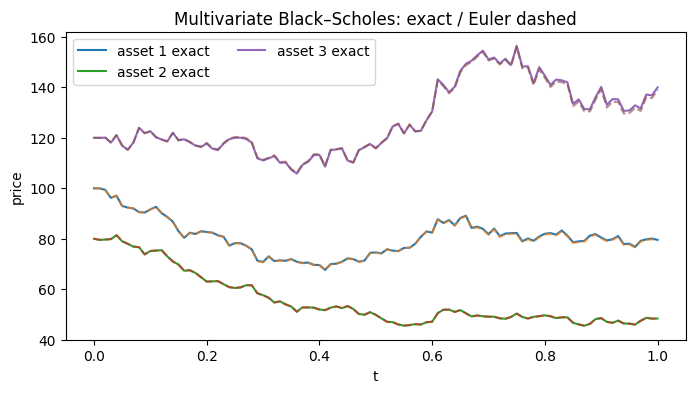

In [3]:
T,N=1.0,100; dt=T/N; d=3
S0=np.array([100.,80.,120.]); mu=np.array([.06,.03,.08])
Sigma=np.array([[.20,0,0],[.10,.18,0],[.06,.04,.22]])
a=Sigma@Sigma.T
dW=np.sqrt(dt)*rng.standard_normal((N,d)); t=np.linspace(0,T,N+1)
Sx=np.empty((N+1,d)); Se=np.empty((N+1,d)); Sx[0]=Se[0]=S0
for n in range(N):
    shock=Sigma@dW[n]
    Sx[n+1]=Sx[n]*np.exp((mu-.5*np.diag(a))*dt+shock)
    Se[n+1]=Se[n]+mu*Se[n]*dt+Se[n]*shock
plt.figure(figsize=(8,4))
for i in range(d):
    plt.plot(t,Sx[:,i],label=f'asset {i+1} exact')
    plt.plot(t,Se[:,i],'--',alpha=.65)
plt.xlabel('t'); plt.ylabel('price'); plt.title('Multivariate Black–Scholes: exact / Euler dashed')
plt.legend(ncol=2); plt.show()

# 3. Multivariate Ornstein–Uhlenbeck process

Consider
$$
dX_t=K(\theta-X_t)dt+\Sigma dW_t,
\qquad X_0=x\in\mathbb R^d.
$$
Assume later that the eigenvalues of $K$ have positive real parts.

## Exercise 3.1 — solve the SDE
Show
$$
X_t=\theta+e^{-Kt}(x-\theta)+\int_0^te^{-K(t-s)}\Sigma\,dW_s.
$$

**Proof sketch.**
Apply the deterministic integrating factor to
$$
Y_t=e^{Kt}(X_t-\theta).
$$
Then $dY_t=e^{Kt}\Sigma dW_t$, and multiplication by $e^{-Kt}$ gives the result.

## Exercise 3.2 — Gaussian marginals
Deduce
$$
X_t\sim N(m_t,C_t),
$$
with
$$
m_t=\theta+e^{-Kt}(x-\theta),
$$
$$
C_t=\int_0^te^{-Ks}\Sigma\Sigma^\top e^{-K^\top s}\,ds.
$$
Show also
$$
\dot C_t=-KC_t-C_tK^\top+\Sigma\Sigma^\top,\qquad C_0=0.
$$

**Proof sketch.** Gaussian distribution is clear. Compute Cov($X_t$) using Ito isometry and doing a change of variable. The resulting integrand $F(s)=e^{-Ks}\Sigma\Sigma^\top e^{-K^\top s}$ satisfies $F'=-KF-FK^\top$. Integrate to obtain the covariance ODE.

## Exercise 3.3 — invariant Gaussian measure
If $\Re\lambda(K)>0$, show
$$
C_t\to C_\infty,
\qquad
KC_\infty+C_\infty K^\top=\Sigma\Sigma^\top.
$$
Hence
$$
\pi=N(\theta,C_\infty)
$$
is invariant.

**Hint:** if $X_0\sim N(\theta,C_\infty)$, compute the covariance of $X_t-\theta$.

**Proof sketch.** Positive real parts give exponential decay of $e^{-Kt}$, hence convergence of the covariance integral. In the covariance ODE, $\dot C_t=F(t)\to0$, so the limit solves the stated Lyapunov equation. We verify invariance.

The two Gaussian terms
$$
e^{-Kt}(X_0-\theta),\qquad \int_0^te^{-K(t-s)}\Sigma dW_s
$$
are independent. Their covariance sum is
$$
e^{-Kt}C_\infty e^{-K^\top t}+C_t=C_\infty.
$$
Thus $X_t\sim N(\theta,C_\infty)$ whenever $X_0\sim\pi$.

**Numerical check.** Sample the exact Gaussian transition with a Cholesky factor of its covariance. Shared normal draws make the plots comparable, but do not give a common Brownian-path coupling.

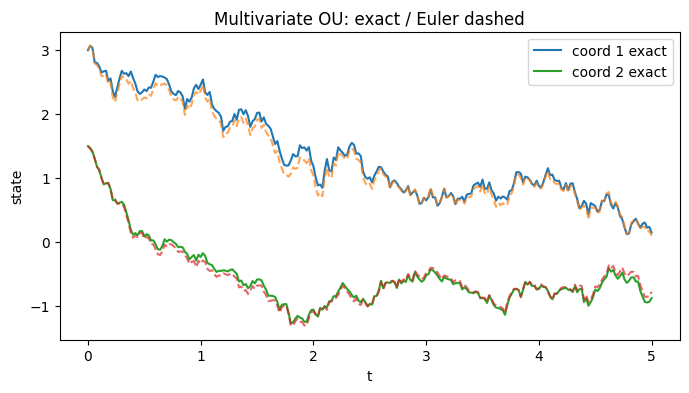

Invariant covariance:
 [[0.1599716  0.02202926]
 [0.02202926 0.10760461]]


In [4]:
T,N=5.0,250; dt=T/N
K=np.array([[1.4,-.35],[.20,.90]])
theta=np.array([1.0,-.5]); Sigma=np.array([[.65,.10],[0,.45]])
Q=Sigma@Sigma.T; x0=np.array([3.0,1.5])
Cinf=solve_continuous_lyapunov(K,Q)
E=expm(-K*dt); Cdt=Cinf-E@Cinf@E.T; Cdt=.5*(Cdt+Cdt.T)
L=np.linalg.cholesky(Cdt+1e-14*np.eye(2))
Z=rng.standard_normal((N,2))
Xx=np.empty((N+1,2)); Xe=np.empty((N+1,2)); Xx[0]=Xe[0]=x0
for n in range(N):
    Xx[n+1]=theta+E@(Xx[n]-theta)+L@Z[n]
    Xe[n+1]=Xe[n]+K@(theta-Xe[n])*dt+Sigma@(np.sqrt(dt)*Z[n])
t=np.linspace(0,T,N+1)
plt.figure(figsize=(8,4))
for i in range(2):
    plt.plot(t,Xx[:,i],label=f'coord {i+1} exact')
    plt.plot(t,Xe[:,i],'--',alpha=.7)
plt.xlabel('t'); plt.ylabel('state'); plt.title('Multivariate OU: exact / Euler dashed'); plt.legend(); plt.show()
print('Invariant covariance:\n',Cinf)

# 4. Generator of a general diffusion

For
$$
dX_t=b(X_t)dt+\sigma(X_t)dW_t,
\qquad a(x)=\sigma(x)\sigma(x)^\top,
$$
Itô's formula motivates
$$
Lf(x)=b(x)\cdot\nabla f(x)+\frac12\operatorname{Tr}(a(x)D^2f(x)).
$$

## Exercise 4.1 — Dynkin formula
Show, under suitable integrability,
$$
\mathbb E_x[f(X_t)]=f(x)+\mathbb E_x\int_0^tLf(X_s)ds.
$$
The local martingale behind this identity is
$$
M_t^f=f(X_t)-f(X_0)-\int_0^tLf(X_s)ds
$$
is a local martingale.

**Proof sketch.**
Integrate Itô's formula:
$$
f(X_t)-f(X_0)=\int_0^tLf(X_s)ds+\int_0^t\nabla f(X_s)^\top\sigma(X_s)dW_s.
$$
The stochastic integral has expectation zero whenever it is a true martingale.

## Exercise 4.2 — basic properties
Check:

1. $L1=0$;
2. $L$ is linear;
3. **positive maximum principle:** if $f$ has a local maximum at an interior point $x$, then $Lf(x)\le0$;
4. for $P_tf(x)=\mathbb E_x[f(X_t)]$, formally
   $$
   \partial_tP_tf=P_tLf=LP_tf.
   $$

**Proof sketch.** Linearity and $L1=0$ follow from differentiation. At an interior maximum the gradient vanishes and the Hessian is negative semidefinite. Dynkin gives $P_tf=f+\int_0^tP_sLf\,ds$, hence $\partial_tP_tf=P_tLf$. For the other equality set $g=P_tf$: the Markov property gives $P_{t+h}f=P_hg$, and $(P_hg-g)/h\to Lg$ when the short-time generator formula applies to $g$.

## Illustration — generator as a short-time derivative
For the 1D OU process and $f(x)=x^2$,
$$
Lf(x)=2\kappa x(\theta-x)+\sigma^2.
$$
Compare this with
$$
\frac{\mathbb E_x[f(X_h)]-f(x)}{h}
$$
using the exact OU transition and one Euler step.

**What to check.** For the exact step use its Gaussian mean $m_h$ and variance $v_h$: $\mathbb E_x[X_h^2]=m_h^2+v_h$. For Euler use mean $x+\kappa(\theta-x)h$ and variance $\sigma^2 h$. Either quotient tends to $Lf(x)$. Sampling noise in the printed estimates is amplified by division by $h$.

In [5]:
kappa,theta0,sigma0=1.7,.8,.6; x=1.3; M=200000
Lf=2*kappa*x*(theta0-x)+sigma0**2
print('Lf(x)=',Lf); print(' h       exact quotient      Euler quotient')
for h in [.2,.1,.05,.02,.01]:
    z=rng.standard_normal(M)
    mean=theta0+np.exp(-kappa*h)*(x-theta0)
    var=sigma0**2*(1-np.exp(-2*kappa*h))/(2*kappa)
    Xx=mean+np.sqrt(var)*z
    Xe=x+kappa*(theta0-x)*h+sigma0*np.sqrt(h)*z
    qx=(np.mean(Xx**2)-x**2)/h; qe=(np.mean(Xe**2)-x**2)/h
    print(f'{h:5.3f}    {qx:12.6f}      {qe:12.6f}')

Lf(x)= -1.85
 h       exact quotient      Euler quotient
0.200       -1.509322         -1.706496
0.100       -1.661805         -1.772883
0.050       -1.768085         -1.828088
0.020       -1.788947         -1.813294
0.010       -1.828806         -1.841303


# 5. Affine transforms

For an affine process, the transform takes the form
$$
\mathbb E_x[e^{\langle z,X_t\rangle}]
=\exp(\phi(t,z)+\langle\psi(t,z),x\rangle)
$$
on its transform domain. Its exponent is affine in the initial state $x$. Imaginary arguments give Fourier transforms; negative real arguments give Laplace transforms for nonnegative states. The backward equation reduces to ODEs for the coefficients.

## 5.1 CIR process

Consider
$$
dX_t=\kappa(\theta-X_t)\,dt+\sigma\sqrt{X_t}\,dW_t,
\qquad X_0=x\ge0.
$$

Its generator is
$$
Lf(x)
=
\kappa(\theta-x)f'(x)
+
\frac12\sigma^2x f''(x).
$$

Because $X_t\ge0$, the natural object is the **Laplace transform**
$$
L_t(u;x)=\mathbb E_x[e^{-uX_t}],
\qquad u\ge0.
$$

### Exercise 5.1 — derive the Riccati equations

Use the exponential-affine ansatz
$$
L_t(u;x)
=
\exp\big(-\phi(t,u)-\psi(t,u)x\big).
$$

Show that
$$
\dot\psi
=
-\kappa\psi-\frac{\sigma^2}{2}\psi^2,
\qquad
\psi(0,u)=u,
$$
and
$$
\dot\phi
=
\kappa\theta\psi,
\qquad
\phi(0,u)=0.
$$

**Proof sketch.** For $g=e^{-\phi-\psi x}$, hold $t$ fixed when applying $L$. Then $g_x=-\psi g$, $g_{xx}=\psi^2g$, and matching the constant and $x$ terms in $\partial_tg=Lg$ gives the Riccati equations. For $u>0$, $y=1/\psi$ solves $y'=\kappa y+\sigma^2/2$, so
$$
c_t=\frac{\sigma^2}{2\kappa}(1-e^{-\kappa t}),\qquad
\psi=\frac{ue^{-\kappa t}}{1+c_tu},\qquad
\phi=\frac{2\kappa\theta}{\sigma^2}\log(1+c_tu).
$$
For $u=0$ both coefficients vanish.

### Illustration — CIR Laplace transform: Riccati versus Euler

For a grid $u\ge0$, compare $u\longmapsto \mathbb E[e^{-uX_T}]$
with the empirical Euler transform
$u\longmapsto
\frac1M\sum_{m=1}^M e^{-uX_T^{E,(m)}}.$

A naive Euler step may leave the state space $[0,\infty)$.  
For this preview we project negative Euler values back to zero.


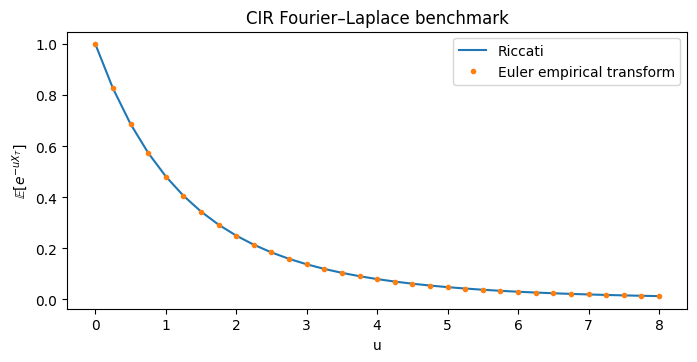

maximum absolute transform discrepancy = 0.00032690680930247407


In [6]:
# CIR: Laplace transform from Riccati versus empirical Euler transform

T = 1.5
kappa, theta_cir, sigma_cir = 2.0, 0.8, 0.7
x0_cir = 0.25

def cir_laplace_riccati(u, T=T):
    u = np.asarray(u, dtype=float)
    cT = sigma_cir**2/(2*kappa) * (1 - np.exp(-kappa*T))
    psi = u*np.exp(-kappa*T)/(1 + cT*u)
    phi = (2*kappa*theta_cir/sigma_cir**2)*np.log(1 + cT*u)
    return np.exp(-phi - psi*x0_cir)

# Euler Monte Carlo
M = 50_000
N = 400
dt = T/N

X_cir_euler = np.full(M, x0_cir)

for _ in range(N):
    z = rng.standard_normal(M)
    xp = np.maximum(X_cir_euler, 0.0)
    x_new = (X_cir_euler
             + kappa*(theta_cir-xp)*dt
             + sigma_cir*np.sqrt(xp)*np.sqrt(dt)*z)
    X_cir_euler = np.maximum(x_new, 0.0)

u_grid = np.linspace(0.0, 8.0, 33)
laplace_riccati = cir_laplace_riccati(u_grid)
laplace_euler = np.array([
    np.mean(np.exp(-u*X_cir_euler)) for u in u_grid
])

plt.figure(figsize=(8, 3.6))
plt.plot(u_grid, laplace_riccati, label="Riccati")
plt.plot(u_grid, laplace_euler, "o", ms=3, label="Euler empirical transform")
plt.xlabel("u")
plt.ylabel(r"$\mathbb{E}[e^{-uX_T}]$")
plt.title("CIR Fourier–Laplace benchmark")
plt.legend()
plt.show()

print("maximum absolute transform discrepancy =",
      np.max(np.abs(laplace_riccati-laplace_euler)))

## 5.2 Heston model

Let
$$
X_t=\log S_t.
$$
Under a pricing measure,
$$
dX_t
=
\left(r-q-\frac12V_t\right)dt+\sqrt{V_t}\,dW_t^1,
$$
$$
dV_t
=
\kappa(\theta-V_t)dt+\xi\sqrt{V_t}\,dW_t^2,
$$
with
$$
d[W^1,W^2]_t=\rho\,dt.
$$

The state space is $\mathbb R\times\mathbb R_+$.  
The natural joint transform is therefore **Fourier in $X$** and **Laplace in $V$**:
$$
F_T(u,\eta)
=
\mathbb E_{x,v}
\left[
e^{iuX_T-\eta V_T}
\right],
\qquad
u\in\mathbb R,\ \eta\ge0.
$$

### Exercise 5.2 — derive the affine Riccati system

Use
$$
\mathbb E_{x,v}
\left[
e^{iuX_t+wV_t}
\right]
=
\exp\left(
\phi(t)+iux+\psi(t)v
\right).
$$

Show that
$$
\dot\psi
=
\frac12\xi^2\psi^2
+
(\rho\xi iu-\kappa)\psi
-\frac12(u^2+iu),
\qquad
\psi(0)=w,
$$
and
$$
\dot\phi
=
iu(r-q)+\kappa\theta\psi,
\qquad
\phi(0)=0.
$$

For the joint Fourier–Laplace transform take
$$
w=-\eta.
$$

For the characteristic function of $X_T$, take the special case
$$
\eta=0.
$$

### Illustration — joint Heston Fourier–Laplace transform

Fix $\eta>0$. We compare

$$
u\longmapsto
\mathbb E[e^{iuX_T-\eta V_T}]
$$

computed by

1. solving the complex Riccati system;
2. simulating many Euler trajectories and taking the empirical transform
   $$
   \frac1M\sum_{m=1}^M
   e^{iuX_T^{E,(m)}-\eta V_T^{E,(m)}}.
   $$

Since the transform is complex-valued, we inspect both real and imaginary parts.

**What to check.** Evaluate $e^{iuX_T-\eta V_T}$ on each simulated terminal pair and average; compare the real and imaginary parts separately against the Riccati calculation.

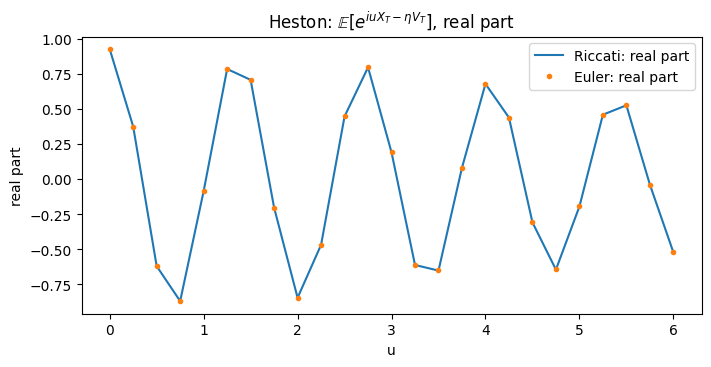

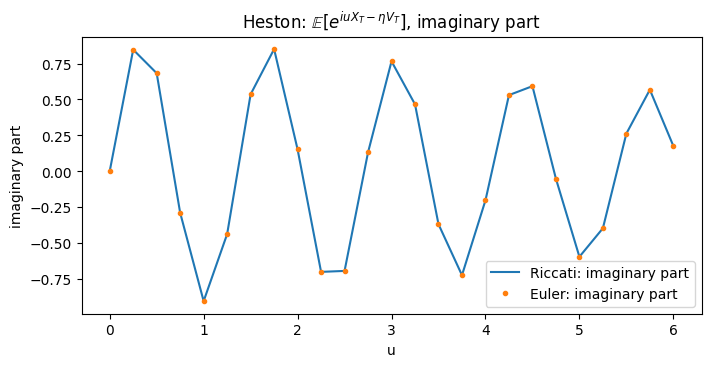

maximum complex transform discrepancy = 0.0014609734718055776


In [7]:
# Heston joint Fourier–Laplace transform:
# Riccati ODE versus empirical Euler transform

r, q = 0.02, 0.0
kappa_h, theta_h, xi_h, rho = 1.8, 0.04, 0.45, -0.7
x0_h, v0_h = np.log(100.0), 0.04
T_h = 1.0
eta_laplace = 2.0

def heston_joint_transform_riccati(u, eta=eta_laplace, T=T_h):
    w = -eta

    def rhs(t, y):
        phi, psi = y
        dpsi = (0.5*xi_h**2*psi**2
                + (rho*xi_h*1j*u-kappa_h)*psi
                - 0.5*(u**2 + 1j*u))
        dphi = 1j*u*(r-q) + kappa_h*theta_h*psi
        return np.array([dphi, dpsi], dtype=complex)

    sol = solve_ivp(
        rhs, (0.0, T), np.array([0j, w+0j]),
        rtol=1e-10, atol=1e-12
    )
    phi_T, psi_T = sol.y[:, -1]
    return np.exp(phi_T + 1j*u*x0_h + psi_T*v0_h)

# Euler Monte Carlo
M_h = 50_000
N_h = 400
dt_h = T_h/N_h

X_heston_euler = np.full(M_h, x0_h)
V_heston_euler = np.full(M_h, v0_h)

for _ in range(N_h):
    z1 = rng.standard_normal(M_h)
    z2 = rng.standard_normal(M_h)

    dW1 = np.sqrt(dt_h)*z1
    dW2 = np.sqrt(dt_h)*(rho*z1 + np.sqrt(1-rho**2)*z2)

    vp = np.maximum(V_heston_euler, 0.0)

    X_heston_euler += (
        (r-q-0.5*vp)*dt_h
        + np.sqrt(vp)*dW1
    )

    v_new = (
        V_heston_euler
        + kappa_h*(theta_h-vp)*dt_h
        + xi_h*np.sqrt(vp)*dW2
    )
    V_heston_euler = np.maximum(v_new, 0.0)

u_grid_h = np.linspace(0.0, 6.0, 25)

tf_riccati = np.array([
    heston_joint_transform_riccati(u) for u in u_grid_h
])

tf_euler = np.array([
    np.mean(np.exp(1j*u*X_heston_euler
                   - eta_laplace*V_heston_euler))
    for u in u_grid_h
])

plt.figure(figsize=(8, 3.6))
plt.plot(u_grid_h, tf_riccati.real, label="Riccati: real part")
plt.plot(u_grid_h, tf_euler.real, "o", ms=3, label="Euler: real part")
plt.xlabel("u")
plt.ylabel("real part")
plt.title(r"Heston: $\mathbb{E}[e^{iuX_T-\eta V_T}]$, real part")
plt.legend()
plt.show()

plt.figure(figsize=(8, 3.6))
plt.plot(u_grid_h, tf_riccati.imag, label="Riccati: imaginary part")
plt.plot(u_grid_h, tf_euler.imag, "o", ms=3, label="Euler: imaginary part")
plt.xlabel("u")
plt.ylabel("imaginary part")
plt.title(r"Heston: $\mathbb{E}[e^{iuX_T-\eta V_T}]$, imaginary part")
plt.legend()
plt.show()

print("maximum complex transform discrepancy =",
      np.max(np.abs(tf_riccati-tf_euler)))

## 5.3 Carr–Madan: from the transform to call prices

For $k=\log K$, let $C(k)=e^{-rT}\mathbb E[(e^{X_T}-e^k)^+]$ be the price of a European call (be convinced that this formulation makes sense. In what range does $k$ vary?). As $k\to-\infty$ this tends to a positive constant, thus motivating the use of damping: $c_\alpha(k)=e^{\alpha k}C(k)$. Choose $\alpha>0$ with $\mathbb E[e^{(\alpha+1)X_T}]<\infty$. With $\varphi_T(z)=\mathbb E[e^{izX_T}]$,
$$
\widehat c_\alpha(v)=
\frac{e^{-rT}\varphi_T(v-i(\alpha+1))}{(\alpha+iv)(\alpha+1+iv)},
\qquad
C(k)=\frac{e^{-\alpha k}}{\pi}\int_0^\infty
\Re[e^{-ivk}\widehat c_\alpha(v)]\,dv.
$$
referred to as the Carr-Madan formula.

### Exercise 5.3 — derive the Carr–Madan denominator

Starting from $C(k)$ given above,
formally compute
$$
\int_{\mathbb R}e^{ivk}e^{\alpha k}C(k)\,dk.
$$

Interchange the $k$- and $x$-integrals (justifying) and show that the inner integral gives
$$
\frac{e^{(\alpha+1+iv)x}}
{(\alpha+iv)(\alpha+1+iv)}.
$$

Use
$$
(\alpha+iv)(\alpha+1+iv)
=
\alpha^2+\alpha-v^2+i(2\alpha+1)v
$$
to recover the Carr–Madan formula.

**Proof sketch.** Fix terminal log-price $x$ and put $\beta=\alpha+iv$. Integrating over strikes where the payoff is positive gives
$$
\int_{-\infty}^x e^{\beta k}(e^x-e^k)\,dk
=e^{(\beta+1)x}\left(\frac1\beta-\frac1{\beta+1}\right)
=\frac{e^{(\beta+1)x}}{\beta(\beta+1)}.
$$
At $v=0$ the moment condition gives absolute integrability, hence Fubini for every real $v$. Averaging over $X_T$ yields the shifted characteristic function.

### How FFT works, and its link to Carr-Madan

For an input array $a_0,\ldots,a_{N-1}$, the **discrete Fourier transform (DFT)**
computes
$$
F_m=\sum_{j=0}^{N-1}a_j e^{-2\pi ijm/N},
\qquad m=0,\ldots,N-1.
$$
Computing each sum separately costs $O(N^2)$ operations. The **fast Fourier
transform (FFT)** computes the same sums by reusing calculations.

Assume $N$ is a power of two. Split the input into its even and odd entries:
$(a_0,a_2,\ldots)$ and $(a_1,a_3,\ldots)$. Let $E_m$ and $O_m$ be their
DFTs, each of size $N/2$, and write $\omega_N=e^{-2\pi i/N}$. The identities
$\omega_N^2=\omega_{N/2}$ and $\omega_N^{N/2}=-1$ give
$$
\begin{aligned}
F_m&=E_m+\omega_N^mO_m,\\
F_{m+N/2}&=E_m-\omega_N^mO_m,
\qquad 0\leq m<N/2.
\end{aligned}
$$
Thus two half-sized transforms supply all $N$ outputs. Repeat the splitting until
reaching arrays of size one. There are $\log_2N$ levels, each requiring $O(N)$ work,
so the total cost is $O(N\log N)$.

**For Carr-Madan**, sampling the pricing integral on matching regular frequency and
log-strike grids produces precisely these Fourier sums. The inputs $a_j$ contain
weighted characteristic-function values: one FFT supplies the sums for all grid
strikes. Taking real parts and applying the damping correction gives the prices.
The integral approximation comes from the frequency cutoff and grid choices.
The FFT evaluates the resulting sums efficiently, with floating-point rounding
as its numerical error.

### Illustration — Heston calls from Carr–Madan versus Euler Monte Carlo

For the FFT implementation below, the Heston characteristic function is evaluated by the
**closed-form solution of the same Riccati system**. This is computationally preferable
to solving thousands of ODEs separately.

We then compare Carr–Madan prices at several strikes with the Euler Monte Carlo sample
already generated above.

**What to check.** The target is the discounted Heston payoff expectation. FFT approximates its Fourier inversion on a grid; Euler averages discounted simulated payoffs. The error bars show sampling error and exclude Euler bias.

 strike     Carr-Madan       Euler MC       MC s.e.
   80.0       23.17307       23.20466       0.06921
   90.0       15.10808       15.12878       0.05917
  100.0        8.39484        8.40246       0.04592
  110.0        3.66655        3.67852       0.03091
  120.0        1.16411        1.18975       0.01766


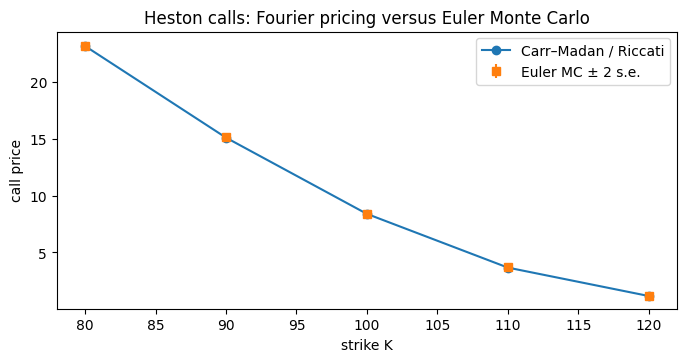

In [8]:
# Closed-form solution of the Heston Riccati system for w=0.
# This is the characteristic function needed by Carr–Madan.

def heston_cf_closed_riccati(u, T=T_h):
    u = np.asarray(u, dtype=complex)

    beta = kappa_h - rho*xi_h*1j*u
    d = np.sqrt(beta**2 + xi_h**2*(u**2 + 1j*u))
    g = (beta-d)/(beta+d)
    exp_dt = np.exp(-d*T)

    D = ((beta-d)/xi_h**2
         * (1-exp_dt)/(1-g*exp_dt))

    C = (1j*u*(r-q)*T
         + (kappa_h*theta_h/xi_h**2)
         * ((beta-d)*T
            - 2*np.log((1-g*exp_dt)/(1-g))))

    return np.exp(C + D*v0_h + 1j*u*x0_h)


def carr_madan_fft(alpha=1.25, N_fft=4096, eta_v=0.05):
    # Frequency grid
    v = np.arange(N_fft)*eta_v

    # Complex shift required by damping
    z = v - 1j*(alpha+1.0)
    phi = heston_cf_closed_riccati(z)

    denominator = (
        alpha**2 + alpha - v**2
        + 1j*(2*alpha+1)*v
    )

    psi = np.exp(-r*T_h)*phi/denominator

    # Dual log-strike grid
    lambda_k = 2*np.pi/(N_fft*eta_v)
    b = 0.5*N_fft*lambda_k
    k_grid = -b + lambda_k*np.arange(N_fft)

    # Trapezoidal weight at v=0
    weights = np.ones(N_fft)
    weights[0] = 0.5

    fft_input = (
        np.exp(1j*b*v)
        * psi
        * eta_v
        * weights
    )

    fft_values = np.fft.fft(fft_input)

    call_grid = (
        np.exp(-alpha*k_grid)
        / np.pi
        * np.real(fft_values)
    )

    return k_grid, call_grid


k_grid, call_grid = carr_madan_fft()

strikes = np.array([80.0, 90.0, 100.0, 110.0, 120.0])

cm_prices = np.interp(
    np.log(strikes),
    k_grid,
    call_grid
)

S_T_euler = np.exp(X_heston_euler)
mc_prices = np.array([
    np.exp(-r*T_h)
    * np.mean(np.maximum(S_T_euler-K, 0.0))
    for K in strikes
])

mc_se = np.array([
    np.exp(-r*T_h)
    * np.std(np.maximum(S_T_euler-K, 0.0), ddof=1)
    / np.sqrt(M_h)
    for K in strikes
])

print(" strike     Carr-Madan       Euler MC       MC s.e.")
for K, pcm, pmc, se in zip(strikes, cm_prices, mc_prices, mc_se):
    print(f"{K:7.1f}     {pcm:10.5f}     {pmc:10.5f}     {se:9.5f}")

plt.figure(figsize=(8, 3.6))
plt.plot(strikes, cm_prices, "o-", label="Carr–Madan / Riccati")
plt.errorbar(strikes, mc_prices, yerr=2*mc_se, fmt="s", label="Euler MC ± 2 s.e.")
plt.xlabel("strike K")
plt.ylabel("call price")
plt.title("Heston calls: Fourier pricing versus Euler Monte Carlo")
plt.legend()
plt.show()